In [2]:
import mediapipe as mp 
import cv2
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


In [3]:
PROJECT_ROOT = Path.cwd().parent

mpHands = mp.solutions.hands
mpDraw = mp.solutions.drawing_utils
hands = mpHands.Hands(
    static_image_mode=True,
    max_num_hands=1,
    model_complexity=1,
    min_detection_confidence=0.7
)

for a single image from the dataset folder B:


hand detected
number of landmarks 21


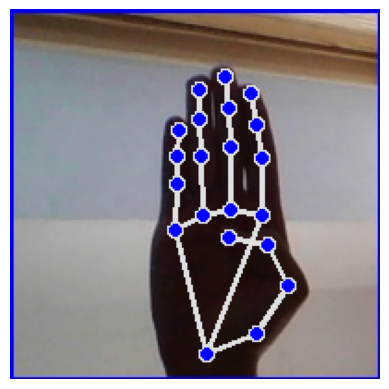

In [4]:
image_path = next (
    (PROJECT_ROOT / "datasets" / "asl_alphabet_train_set"/"B").glob("*.jpg")
)

image = cv2.imread(str(image_path))

img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
results = hands.process(img_rgb)

if results.multi_hand_landmarks:
   print("hand detected")
   print("number of landmarks",len( results.multi_hand_landmarks[0].landmark))


   annotated_img = img_rgb.copy()
   mpDraw.draw_landmarks(
      annotated_img,
      results.multi_hand_landmarks[0],
      mpHands.HAND_CONNECTIONS
   )

   plt.imshow(annotated_img)
   plt.axis("off")
   plt.show()

else:
   print("no hand detected" )


In [8]:
if results.multi_hand_landmarks:
    hand_landmarks = results.multi_hand_landmarks[0]
    landmark_data = []

    for lm in hand_landmarks.landmark:
        landmark_data.append([lm.x,lm.y,lm.z])
print("total number of landmarks", len(landmark_data))
print("first landmark", landmark_data[0])
print("size of landmark data", np.array(landmark_data).shape)



total number of landmarks 21
first landmark [0.5308700799942017, 0.9306913614273071, 8.122291319523356e-07]
size of landmark data (21, 3)


for 100 images present in the dataset:

In [4]:

img_paths = []
labels =[]
dataset_path = PROJECT_ROOT / "datasets" / "asl_alphabet_train_set"  
class_folders =[folder for folder in dataset_path.iterdir() if folder.is_dir()] 
print(len(class_folders))

for folder in class_folders:
    label = folder.name
    for img_path in folder.glob("*.jpg"):
        img_paths.append(img_path)
        labels.append(label)



29


In [9]:

landmark_dataset = []
landmark_labels = []
failed_img = []


for img_path, label in zip(img_paths[:100], labels[:100]):

    
    image = cv2.imread(str(img_path))

    
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    
    results = hands.process(image_rgb)

    
    if results.multi_hand_landmarks:

        hand_landmarks = results.multi_hand_landmarks[0]

        
        coordinates = []

        for lm in hand_landmarks.landmark:
            coordinates.append([lm.x, lm.y, lm.z])

        landmark_dataset.append(coordinates)
        landmark_labels.append(label)

    else:
        failed_img.append((img_paths," detection failed"))

print("Images processed:", 100)
print("Images failed to detect", len(failed_img))
print("Successful detections:", len(landmark_dataset))
print("Landmark labels:", len(landmark_labels))

Images processed: 100
Images failed to detect 13
Successful detections: 87
Landmark labels: 87


In [6]:
landmark_array = np.array(landmark_dataset)

print("Dataset shape:", landmark_array.shape)


print("Contains infinity:", np.isinf(landmark_array).any())

x_coordinates = landmark_array[:, :, 0]
y_coordinates = landmark_array[:, :, 1]
z_coordinates = landmark_array[:, :, 2]

print("X range:", x_coordinates.min(), "to", x_coordinates.max())
print("Y range:", y_coordinates.min(), "to", y_coordinates.max())
print("Z range:", z_coordinates.min(), "to", z_coordinates.max())

Dataset shape: (9, 21, 3)
Contains infinity: False
X range: 0.325301855802536 to 0.9271397590637207
Y range: 0.17824770510196686 to 0.7897084355354309
Z range: -0.14723224937915802 to 0.002607491333037615


In [7]:
print(len(img_paths))
print(len(labels))



87000
87000
